# Analyse exploratoire des données

## 1. Imports et premières informations sur le dataframe

### Points à retenir :
- Les notes données, et donc les moyennes, sont basées ici uniquement sur les personnes qui ont mis un avis.
- Imdb, plateforme Américaine, note plus favorablement qu'Allocine, plateforme Française
- En février 2026, pour la série 'A knight of the Seven Kingdoms', 60% des notes données sont des 10. Deux hypothèses :
1. La hype : les épisodes les mieux notés de la série sont sortis en février. Les fans de Game of Thrones ont pu regarder dès la sortie et donner une très bonne note.
2. Une opération pour améliorer la note, avec de nombreux avis donnés, a eu lieu.
- J'ai donc choisi de donner un poids de 80/100 à ces notes... pour apprendre à le faire. Dans le Power BI, je garderai le poids normal des notes.

Voici donc les moyennes pour chaque série avec les intervalles de confiance :
A Knight of the Seven Kingdoms : 8,11 [7.96 - 8.26]
King & Conqueror : 4,38 [3.98 - 4.79]

L'analyse des avis sera faite dans un second temps pour plus d'enseignements.

In [16]:
# Import des librairies pour l'analyse, la datavisualisation et les calculs statistiques
import numpy as np 
import pandas as pd
import seaborn as sns
import os
from scipy.stats import t
from statistics import variance, mean 
from scipy.stats import skew, kurtosis,bootstrap


In [17]:
# Import du dataframe
df = pd.read_csv("../data/data_clean.csv")
df.head()

,notes,avis,dates,series,allocine_id,review_id,plateforme
0,4,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,28230,282301,Allocine
1,5,Très bonne série. Des épisodes trop court tr...,2026-02-07,A Knight of the Seven Kingdoms,28230,282302,Allocine
2,5,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,28230,282303,Allocine
3,5,J'en suis au 4ème épisode et pour l'instant j'...,2026-02-06,A Knight of the Seven Kingdoms,28230,282304,Allocine
4,5,"Encore un grand cru, un bijoux, du caviar, ou ...",2026-02-10,A Knight of the Seven Kingdoms,28230,282305,Allocine


In [18]:
# Principales informations
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   notes        199 non-null    int64
 1   avis         199 non-null    str  
 2   dates        199 non-null    str  
 3   series       199 non-null    str  
 4   allocine_id  199 non-null    int64
 5   review_id    199 non-null    int64
 6   plateforme   199 non-null    str  
dtypes: int64(3), str(4)
memory usage: 11.0 KB


## 2. Distribution des séries et des plateformes

In [19]:
# Ditribution des séries
print(df['series'].value_counts(), '\n')
print(df['series'].value_counts(normalize=True))  # Afficher en proportion 

# Prépondérance importante de la série 'A knight of the seven kingdoms'

series
A Knight of the Seven Kingdoms    165
King & Conqueror                   34
Name: count, dtype: int64 

series
A Knight of the Seven Kingdoms    0.829146
King & Conqueror                  0.170854
Name: proportion, dtype: float64


In [20]:
print('Statistiques sur la série : A knight of the seven kingdoms :\n', df[df['series'] == 'A Knight of the Seven Kingdoms']['notes'].describe() )
print()
print('Statistiques sur la série King & Conquerer :\n', df[df['series'] == 'King & Conqueror']['notes'].describe())

# A Knight of the Sevent Kingdoms a des notes nettement meilleures que King & Conqueror.

Statistiques sur la série : A knight of the seven kingdoms :
 count    165.00000
mean       3.50303
std        1.56027
min        0.00000
25%        2.00000
50%        4.00000
75%        5.00000
max        5.00000
Name: notes, dtype: float64

Statistiques sur la série King & Conquerer :
 count    34.000000
mean      1.764706
std       1.498663
min       0.000000
25%       1.000000
50%       1.000000
75%       2.750000
max       5.000000
Name: notes, dtype: float64


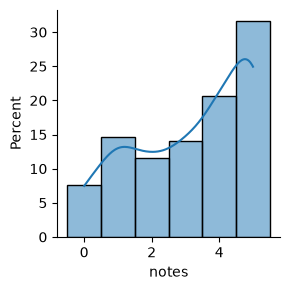

In [21]:
# Visualisons les distributions

g = sns.FacetGrid(df)
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

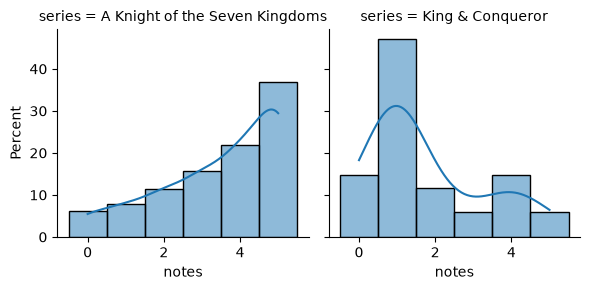

In [22]:
g = sns.FacetGrid(df, col="series")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

## 3. Distribution selon la date

annee-mois
202508      1
202509      5
202601     21
202602    109
202603     44
202604      5
202605      2
202606      1
202607      4
202608      4
202609      2
202610      1
Name: count, dtype: int64


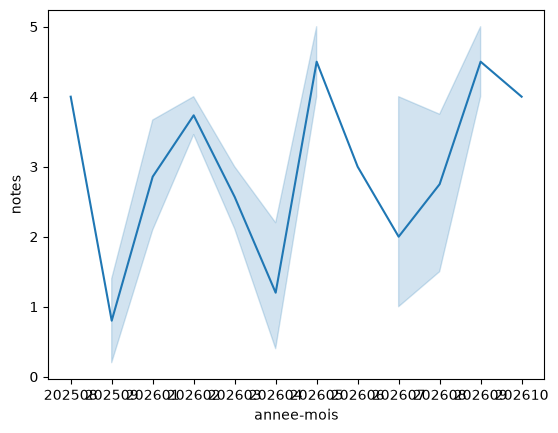

In [23]:
# Regardons si la date a eu un impact sur les notes données

df['dates'] = pd.to_datetime(df['dates']) # Conversion

# Création d'une colonne pour trier selon le format suivant 'YYYYMM'
df['annee-mois'] = df['dates'].dt.strftime('%Y%m')
print(df['annee-mois'].value_counts().sort_index())

# Création graphique
df_dates = df.set_index('annee-mois').sort_index()
sns.lineplot(data=df_dates["notes"].sort_index());

# Nous observons une dynamique différente entre la fin de l'année dernière, avec des notes globalement
# inférieurs à 5, et 2026, où les notes remontent fortement.

In [24]:
# Regardons de plus près les statistiques par mois.

df.groupby(['annee-mois'])['notes'].describe()

,count,mean,std,min,25%,50%,75%,max
annee-mois,,,,,,,,
202508,1.0,4.000000,NaN,4.0,4.00,4.0,4.00,4.0
202509,5.0,0.800000,0.836660,0.0,0.00,1.0,1.00,2.0
202601,21.0,2.857143,1.851640,0.0,2.00,3.0,4.00,5.0
202602,109.0,3.733945,1.525355,0.0,3.00,4.0,5.00,5.0
202603,44.0,2.568182,1.515773,0.0,1.00,3.0,4.00,5.0
202604,5.0,1.200000,1.095445,0.0,1.00,1.0,1.00,3.0
202605,2.0,4.500000,0.707107,4.0,4.25,4.5,4.75,5.0
202606,1.0,3.000000,NaN,3.0,3.00,3.0,3.00,3.0
202607,4.0,2.000000,2.000000,1.0,1.00,1.0,2.00,5.0


Dates de sortie des épisodes : 
24 août 2025 au 5 octobre pour King & Conquer sur BBC One, du 19 janvier au 23 février 2026 pour A knight of the seven kingdoms.

Le mois de février, la médiane à 10 est impressionnante. Deux hypothèses ici : 
- Les épisodes sortis en février ont eu un excellent accueil.
- Une campagne pour promouvoir la série a eu lieu pour mettre de bonnes notes, notamment sur Imdb.

Le Quartile de 25% à 9 me met la puce à l'oreille. 

Vérifions si nous retrouvons les mêmes tendances sur les deux plateformes pour la série 'A Knight of the Seven Kingdoms'.

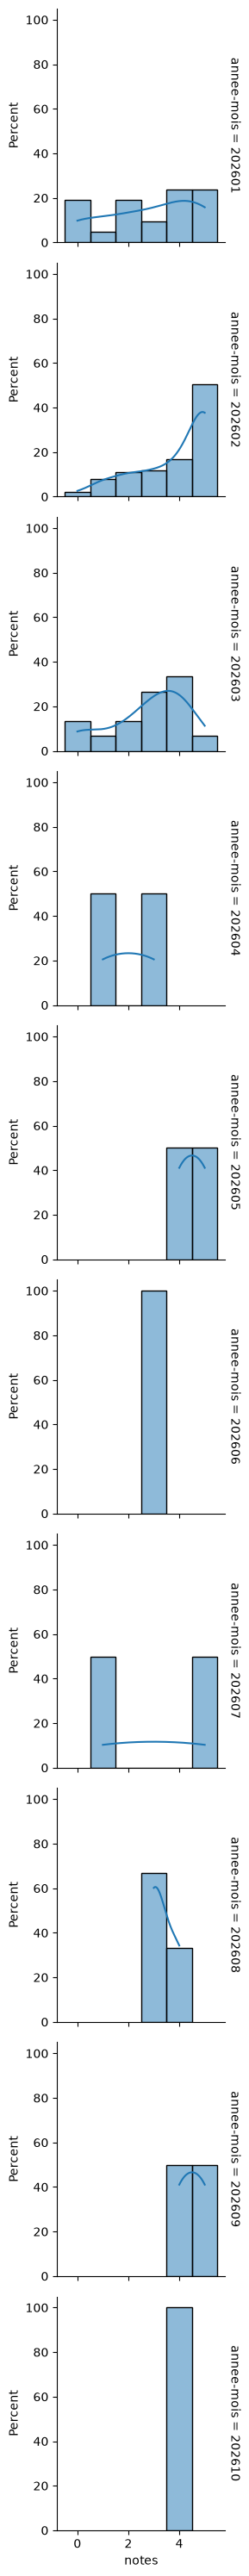

In [25]:
# Création d'un dataframe ciblé sur 2026 et A Knight of the Seven Kindgoms
df_2026_knight = df.loc[(df['dates'].dt.year == 2026) & (df['series'] == 'A Knight of the Seven Kingdoms')]

# Visualisation comparée par mois de 2026
g = sns.FacetGrid(df_2026_knight.sort_values('annee-mois'), \
                  row='annee-mois', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

Je pense que mes deux hypothèses sont justes :
1. Les épisodes 3, 4, et 5 de la série ont reçu un très bon accueil : ce sont les meilleurs avec des notes tous supérieurs à 9 dans Imdb.
2. Il est aussi possible que les plus fans de l'univers GOAT aient regardé les épisodes dès leur sortie, et qu'ils soient le plus venus rapidement donner une note positive. Il y a peut-être eu un effet de mode en février.
3. En revanche, je trouve la différence entre février et mars trop différente (environ 60% et 40% de notes à 10). 

Je pense que la hype explique ces notes très fortes. Mais par soucis de pédagogie, je vais baisser le poids des notes données.

## 4. Moyennes des notes par série (avec pondération)

In [26]:
# Statistiques des notes par séries et plateformes avant pondération

print("Statistiques par série")
display(df.groupby(['series'])[('notes')].describe())
print()

Statistiques par série


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
A Knight of the Seven Kingdoms,165.0,3.503030,1.560270,0.0,2.0,4.0,5.00,5.0
King & Conqueror,34.0,1.764706,1.498663,0.0,1.0,1.0,2.75,5.0


Modifications : donner un poids de 0,8 à la réponse lorsque la note est de 10 pour 'A Knight of the Seven Kingdoms' en février 2026 sur Imdb, et  1 pour les autres.

Une pondération à 80% (baisse de 20%) part d'une hypothèse prudente, que la plupart des notes sont sincères, et que, s'il y a eu une campagne, elle se situe à la marge.

## 5. Intervalles de confiances

Calculons maintenant les intervalles de confiance pour les deux séries.

Avec deux cas de figure : 
1. King & Conquerer : pas de modification du poids des réponses
2. A Knight of the Seven Kingdoms : modifications du poids, donc de l'effectif de réponses.

Aides :
https://claude.ai/chat/f112ba51-f00a-46da-9286-042acd2bc990
https://matthwilhelm.github.io/ProbaStat/Tutoriel_Python.html
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html

Sur le skewness et le kurtosis : https://www.datacamp.com/fr/tutorial/understanding-skewness-and-kurtosis


In [27]:
df_king = df[df["series"] == "King & Conqueror"]

print(skew(df_king['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_king['notes'])) # aplatissement — problématique si très élevé

# Asymétrie : les données sont majoritairement inférieures à la moyenne
# Aplatissement : proche de 0, pas de soucis.

0.8476637184930271
-0.5083446712018138


In [28]:
# Cas 1 : King & Conqueror, sans pondération des notes

def int_ech(values, conf=0.95):
    
    n = len(values) # Taille échantillon
    m = np.mean(values) # Moyenne
    s = np.var(values, ddof=1) # Variance

    alpha_half = 1 - (1 - conf) / 2
    ddl = n - 1 # Degré de liberté

    intervalle = np.sqrt(s / n) * t.ppf(alpha_half, ddl)

    return intervalle

intervalle_king = int_ech(df_king['notes'])
intervalle_king_up = np.mean(df_king['notes']) + intervalle_king
intervalle_king_down = np.mean(df_king['notes']) - intervalle_king

print('Intervalle de confiance King & Conqueror : [', intervalle_king_down,'-', intervalle_king_up, ']' )

Intervalle de confiance King & Conqueror : [ 1.2417978138682524 - 2.28761395083763 ]


In [ ]:
# Pour A Knight of the Seven Kingdoms
df_knight = df[df["series"] == "A Knight of the Seven Kingdoms"]


print(skew(df_knight['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_knight['notes'])) # applatissement — problématique si très élevé


intervalle_knight = int_ech(df_knight['notes'])
intervalle_knight_up = np.mean(df_knight['notes']) + intervalle_knight
intervalle_knight_down = np.mean(df_knight['notes']) - intervalle_knight

print('Intervalle de confiance A Knight of the Seven Kingdoms : [', intervalle_knight_down,'-', intervalle_knight_up, ']' )

-0.7930257550211738
-0.49159619922077313
Intervalle de confiance A Knight of the Seven Kingdoms : [ 3.263189822726126 - 3.74287078333448 ]
Intervalle de confiance A Knight of the Seven Kingdoms : [ 3.263189822726126 - 3.74287078333448 ]


In [30]:

# Pour le test, vérification avec le bootstrap.

result = bootstrap(
    (df_knight['notes'].values,),
    np.mean,
    confidence_level=0.95,
    n_resamples=9999,
    method='percentile'
)
print(result.confidence_interval)

ConfidenceInterval(low=np.float64(3.2545454545454544), high=np.float64(3.7333333333333334))
